Task 1: Use Linear Regression to predict Q from the variables n, P, ∆p, and any combinations
thereof that you find relevant. Use the dataset train1.csv as your training data, and test1.csv
as your test data. Report your test error and the parameters of your best-performing regression model.

In [17]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import KFold, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [18]:
# Import data
train = pd.read_csv("../data/case1/train1.csv")
test = pd.read_csv("../data/case1/train1.csv")

# Inspect the data
print(train.head())
print(train.info())
print(train.describe())

# Check the shape
print("Training data:", train.shape)
print("Testing data:", test.shape)

             pump_id  elapsed_s operating_state    speed_rpm     power_w  \
0  99223468_model_01       14.5          stable  4230.396017  669.992714   
1  99223468_model_01       24.5          stable  3796.519900  931.528480   
2  99223468_model_01       34.5          stable  3508.264375  724.198083   
3  99223468_model_01       44.5          stable  1498.405243   99.463217   
4  99223468_model_01       64.5          stable  3224.873653  608.195308   

   inlet_pressure_bar  outlet_pressure_bar  flow_m3_h  
0            1.057136             2.414427   0.652884  
1            2.097392             2.390436  43.040564  
2            2.247896             2.433662  40.939560  
3            2.287246             2.451128  11.857951  
4            2.464618             2.696299  36.000996  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 480 entries, 0 to 479
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0 

In [19]:
# Put this notebook in the same folder as train1.csv and test1.csv.
train_data = pd.read_csv("../data/case1/test1.csv")
test_data = pd.read_csv("../data/case1/train1.csv")

print("Training data:", train_data.shape)
print("Test data:", test_data.shape)
print(train_data.head())
print("Missing values in training data:\n", train_data.isna().sum())

Training data: (120, 8)
Test data: (480, 8)
             pump_id  elapsed_s operating_state    speed_rpm      power_w  \
0  99223468_model_01        4.5          stable  3366.659752   673.895512   
1  99223468_model_01       54.5          stable  4789.551122  2000.894155   
2  99223468_model_01      104.5          stable  2505.468402   268.940786   
3  99223468_model_01      154.5          stable  2215.361812   221.671027   
4  99223468_model_01      204.5          stable  4086.674537   947.129057   

   inlet_pressure_bar  outlet_pressure_bar  flow_m3_h  
0            1.529822             1.770001  37.515511  
1            2.450939             3.231860  49.344893  
2            2.406375             2.881069   7.990913  
3            1.766376             2.144507  11.139878  
4            1.465982             2.754050  10.627591  
Missing values in training data:
 pump_id                0
elapsed_s              0
operating_state        0
speed_rpm              0
power_w                

In [20]:
# Convert speed to thousands of RPM, power to kW,
# and calculate the pressure increase across the pump.
for dataset in [train_data, test_data]:
    dataset["speed_krpm"] = dataset["speed_rpm"] / 1000
    dataset["power_kw"] = dataset["power_w"] / 1000
    dataset["pressure_difference_bar"] = (
        dataset["outlet_pressure_bar"] - dataset["inlet_pressure_bar"]
    )

feature_names = ["speed_krpm", "power_kw", "pressure_difference_bar"]
target_name = "flow_m3_h"

X_train = train_data[feature_names]
y_train = train_data[target_name]
X_test = test_data[feature_names]
y_test = test_data[target_name]

print(X_train.head())

   speed_krpm  power_kw  pressure_difference_bar
0    3.366660  0.673896                 0.240178
1    4.789551  2.000894                 0.780921
2    2.505468  0.268941                 0.474694
3    2.215362  0.221671                 0.378131
4    4.086675  0.947129                 1.288068


In [21]:
# Compare 4 versions of linear regression. using only the training data.
#all trying to predic water flow using punp speed, pump power, pressure difference.
# the degree means how many times we can multiply input features together in one term.
# Degree 1: n, P, delta_p
# Degree 2: also squares and pairwise products
# Degree 3: also cubic combinations
# we test using cross validation of what gives the best predictions.
cross_validation = KFold(n_splits=5, shuffle=True, random_state=42)
results = []

for degree in [1, 2, 3]:
    candidate_model = make_pipeline(
        PolynomialFeatures(degree=degree, include_bias=False),
        LinearRegression()
    )

    fold_rmse = -cross_val_score(
        candidate_model, X_train, y_train,
        cv=cross_validation,
        scoring="neg_root_mean_squared_error"
    )
    results.append({"degree": degree, "mean_cv_rmse": fold_rmse.mean(),
                    "std_cv_rmse": fold_rmse.std()})

cv_results = pd.DataFrame(results)
print(cv_results.to_string(index=False))

best_degree = int(cv_results.loc[cv_results["mean_cv_rmse"].idxmin(), "degree"])
print("\nChosen polynomial degree:", best_degree)

 degree  mean_cv_rmse  std_cv_rmse
      1      3.536451     0.320150
      2      1.136850     0.172961
      3      1.090772     0.351750

Chosen polynomial degree: 3


We used 5-fold cross-validation to perform model selection, progressively increasing the polynomial degree and selecting the model with the lowest average validation RMSE.

**Important distinction: Increasing complexity is the model-building strategy. Cross-validation is the evaluation method used to choose between the models.

In [22]:
#After we chose the model using cross validdation we train with it on ALL the training observations.
best_model = make_pipeline(
    PolynomialFeatures(degree=best_degree, include_bias=False),
    LinearRegression()
)
best_model.fit(X_train, y_train)

# Evaluate the test set only after selecting the model.
predicted_flow = best_model.predict(X_test)

mae = mean_absolute_error(y_test, predicted_flow)
rmse = np.sqrt(mean_squared_error(y_test, predicted_flow))
r2 = r2_score(y_test, predicted_flow)

print(f"Test MAE:  {mae:.4f} m³/h")
print(f"Test RMSE: {rmse:.4f} m³/h")
print(f"Test R²:   {r2:.4f}")

Test MAE:  0.7045 m³/h
Test RMSE: 0.9472 m³/h
Test R²:   0.9947


In [24]:

# Predictions on training and test data
train_predictions = best_model.predict(X_train)
test_predictions = best_model.predict(X_test)

# Calculate errors
train_rmse = np.sqrt(mean_squared_error(y_train, train_predictions))
test_rmse = np.sqrt(mean_squared_error(y_test, test_predictions))

print("Training RMSE:", round(train_rmse, 4))
print("Test RMSE:", round(test_rmse, 4))


Training RMSE: 0.7844
Test RMSE: 0.9472


In [23]:
# Print the fitted intercept and every coefficient.
polynomial_step = best_model.named_steps["polynomialfeatures"]
regression_step = best_model.named_steps["linearregression"]

expanded_feature_names = polynomial_step.get_feature_names_out(feature_names)

print("Intercept:", regression_step.intercept_)
print("\nRegression coefficients:")
for feature, coefficient in zip(expanded_feature_names, regression_step.coef_):
    print(f"{feature:55s} {coefficient: .6f}")

# Coefficients correspond to n in krpm, P in kW, and delta_p in bar.

Intercept: 36.12798828684487

Regression coefficients:
speed_krpm                                              -57.064012
power_kw                                                 483.846168
pressure_difference_bar                                 -145.364583
speed_krpm^2                                             31.726730
speed_krpm power_kw                                     -311.635245
speed_krpm pressure_difference_bar                       49.754630
power_kw^2                                               101.181789
power_kw pressure_difference_bar                         171.878200
pressure_difference_bar^2                               -9.454619
speed_krpm^3                                            -4.417397
speed_krpm^2 power_kw                                    53.990103
speed_krpm^2 pressure_difference_bar                    -7.715730
speed_krpm power_kw^2                                   -48.343782
speed_krpm power_kw pressure_difference_bar             -31.303473
speed

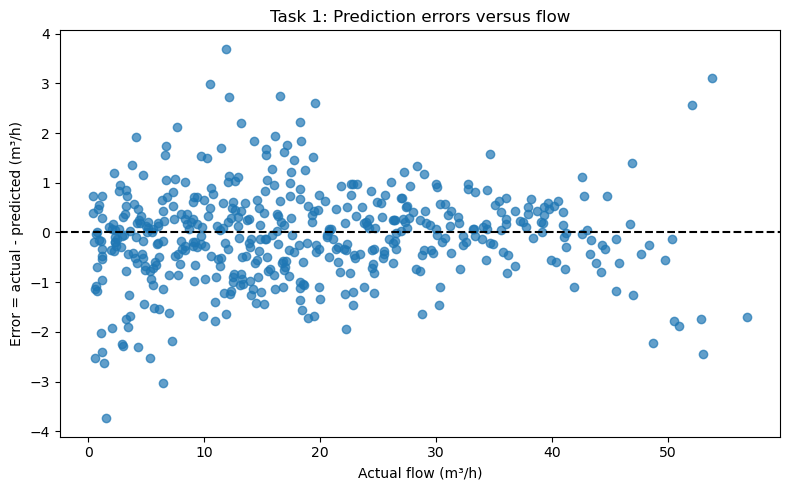

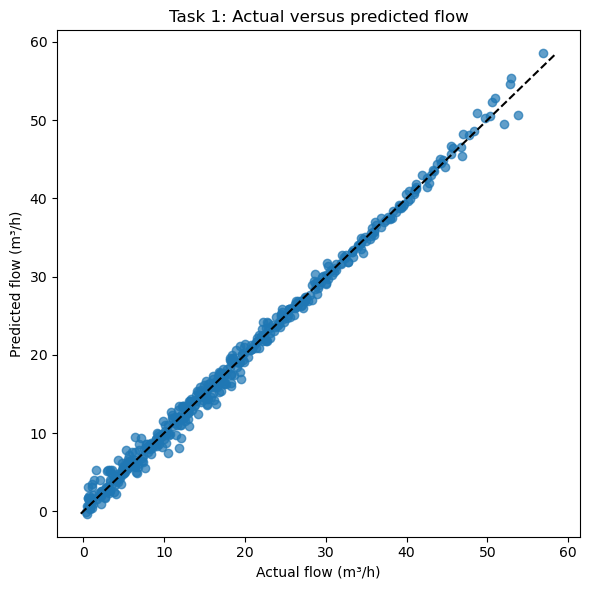

In [25]:
# Plot errors versus true flow rate.
errors = y_test.to_numpy() - predicted_flow
plt.figure(figsize=(8, 5))
plt.scatter(y_test, errors, alpha=0.7)
plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Actual flow (m³/h)")
plt.ylabel("Error = actual - predicted (m³/h)")
plt.title("Task 1: Prediction errors versus flow")
plt.tight_layout()
plt.show()

# Optional: actual versus predicted values.
plt.figure(figsize=(6, 6))
plt.scatter(y_test, predicted_flow, alpha=0.7)
limits = [min(y_test.min(), predicted_flow.min()), max(y_test.max(), predicted_flow.max())]
plt.plot(limits, limits, "k--")
plt.xlabel("Actual flow (m³/h)")
plt.ylabel("Predicted flow (m³/h)")
plt.title("Task 1: Actual versus predicted flow")
plt.tight_layout()
plt.show()

In [26]:
#. Report your test error and the parameters of your best-performing regression model

# TASK 1: Report test errors and model parameters

# Get the trained model
regression = best_model.named_steps["linearregression"]
polynomial = best_model.named_steps["polynomialfeatures"]

# 1. Print selected model
print("Best polynomial degree:", polynomial.degree)

# 2. Print model parameters
print("\nIntercept:", regression.intercept_)

feature_names = polynomial.get_feature_names_out(X_train.columns)

parameters = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": regression.coef_
})

print("\nModel parameters:")
print(parameters.to_string(index=False))

# 3. Predict on test data
y_pred = best_model.predict(X_test)

# 4. Calculate test errors
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("\nTest results:")
print(f"MAE:  {mae:.4f} m³/h")
print(f"RMSE: {rmse:.4f} m³/h")
print(f"R²:   {r2:.4f}")


Best polynomial degree: 3

Intercept: 36.12798828684487

Model parameters:
                                    Feature  Coefficient
                                 speed_krpm   -57.064012
                                   power_kw   483.846168
                    pressure_difference_bar  -145.364583
                               speed_krpm^2    31.726730
                        speed_krpm power_kw  -311.635245
         speed_krpm pressure_difference_bar    49.754630
                                 power_kw^2   101.181789
           power_kw pressure_difference_bar   171.878200
                  pressure_difference_bar^2    -9.454619
                               speed_krpm^3    -4.417397
                      speed_krpm^2 power_kw    53.990103
       speed_krpm^2 pressure_difference_bar    -7.715730
                      speed_krpm power_kw^2   -48.343782
speed_krpm power_kw pressure_difference_bar   -31.303473
       speed_krpm pressure_difference_bar^2    -7.934043
             